This file is for analyzing the results of GRMHD simulations. All analysis is finished and saved in the folder. If you want to rerun the analysis, please set RERUN_ANALYSIS = True.

What is needed:

- `GRMHD/data/grmhdDataOrigin.npy` GRMHD simulation data of different time and different axion fields.
- `GRMHD/data/different_omega/` GRMHD simulation data of different axion omega.

What is generated:

- `GRMHD/grmhdDataAfterImageS.npy` GRMHD simulation data of different time and different axion fields after processing like blurring, ...
- `EVPA.npy` EVPA data calculated from the different time and different axion fields GRMHD data
- `EVPA_1d.npy` EVPA data integrated over radius with 10 degree average
- `EVPA_result.npy` Axion fields effection of EVPA of different axion omega
- `EVPA_phi_10deg_result.npy` Axion fields effection of EVPA of different axion omega, integrated over radius with 10 degree average
- `EVPA_fit_result.npy` Axion fields effection of EVPA of different time
- `EVPA_fit_result_1d.npy` Axion fields effection of EVPA of different time, integrated over radius with 10 degree average

In [1]:
RERUN_ANALYSIS = False

In [2]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from utils.libanaly import Plot_Background,plot_quivers,CircleCalc,ImageS
from scipy.optimize import curve_fit

Load the GRMHD data. The shape of grmhdDataOrigin is (Num, 17, 100, 100, 4):
- Num: Number of simulations of different time. Time step is $0.1 R_g$
- 17: 0 is the simulation without axion field, 1-16 are the simulation with axion field phases from 0 to $2\pi \frac{15}{16}$
- 100x100: simulation result image is 100x100
- 4: I, Q, U, V

In [3]:
# (Num, 17, 100, 100, 4)
grmhdDataOrigin=np.load("data/grmhdDataOrigin.npy",allow_pickle=True)

In [4]:
def getGRMHDDataAfterImageS(grmhdDataOrigin,rotation_angle=0.6*np.pi,gaussian_kernel=None):
    """
    ImageS blurs the data image, and calculates many useful quantities. This function calculates all the data at once.
    """
    shape=grmhdDataOrigin.shape
    shape=(shape[0],shape[1],64,64,4)
    grmhdDataAfterImageS=np.zeros(shape)
    EVPA=np.zeros((shape[0],shape[1],64,64))
    EVPA_1d=np.zeros((shape[0],shape[1],360))
    for t in range(shape[0]):
        print(t)
        for i in range(shape[1]):
            tmp=ImageS(grmhdDataOrigin[t,i],rotation_angle=rotation_angle,gaussian_kernel=gaussian_kernel)
            grmhdDataAfterImageS[t,i,:,:,0]=tmp.I
            grmhdDataAfterImageS[t,i,:,:,1]=tmp.Q
            grmhdDataAfterImageS[t,i,:,:,2]=tmp.U
            grmhdDataAfterImageS[t,i,:,:,3]=tmp.V
            EVPA[t,i]=tmp.evpa/180*np.pi # rad
            EVPA_1d[t,i]=tmp.evpa_phi_10deg/180*np.pi # rad
    return grmhdDataAfterImageS,EVPA,EVPA_1d

This will cost long time, so we save the data in a file, you can load it directly.

In [5]:
if RERUN_ANALYSIS:
    grmhdDataAfterImageS,EVPA,EVPA_1d=getGRMHDDataAfterImageS(grmhdDataOrigin)
    np.save("grmhdDataAfterImageS.npy",grmhdDataAfterImageS)
    np.save("EVPA.npy",EVPA)
    np.save("EVPA_1d.npy",EVPA_1d)

In [5]:
grmhdDataAfterImageS=np.load("grmhdDataAfterImageS.npy")
EVPA=np.load("EVPA.npy")
EVPA_1d=np.load("EVPA_1d.npy")

Plot an average image:

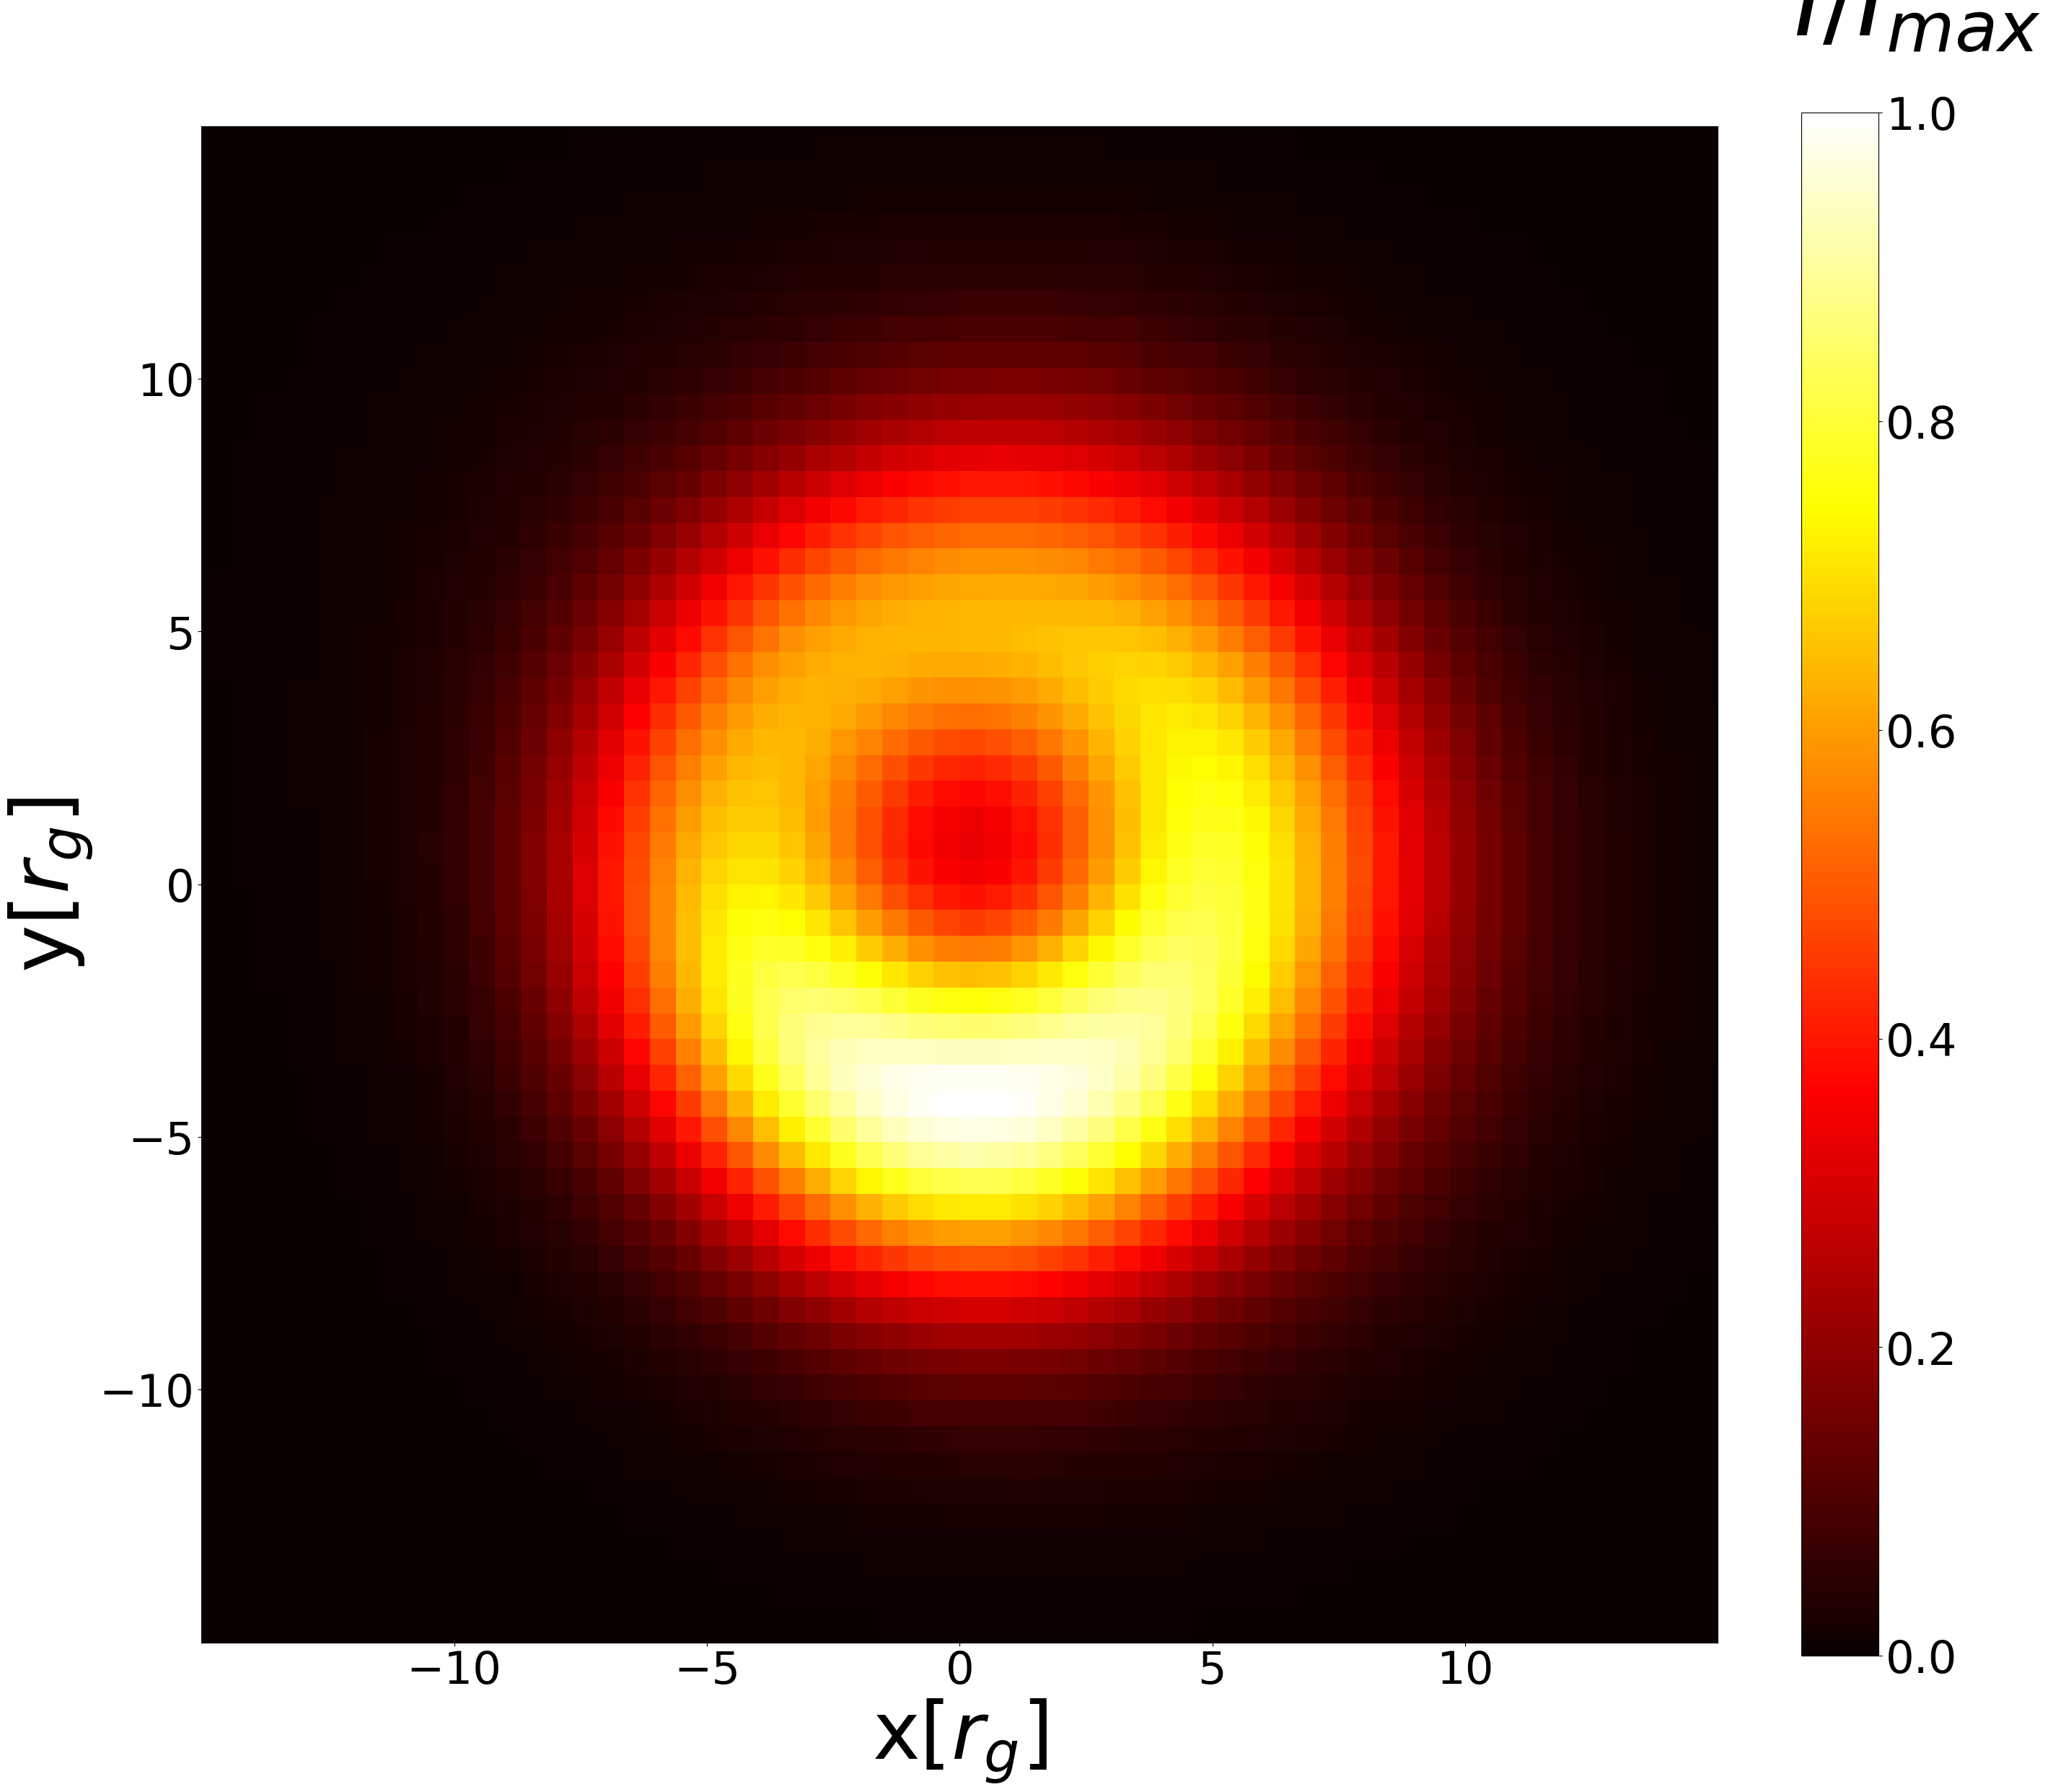

In [6]:
figure,ax0 = plt.subplots(figsize=(30,30)) 
ax0.set_xlim(-15,15)
ax0.set_xlabel('x[$r_g$]',size=80)
ax0.set_ylim(-15,15)
ax0.set_ylabel('y[$r_g$]',size=80)
plt.tick_params(labelsize=45)
plt.xticks([-10,-5,0,5,10])
plt.yticks([-10,-5,0,5,10])
Plot_Background(figure,ax0,np.sum(grmhdDataAfterImageS[:,0,:,:,0],axis=0))
figure.show()

Some functions:

In [7]:
def fit_cos(x):
    if np.isnan(x).any():
        return np.nan
    initial_guess = [0]
    # using curve_fit to fit the data
    popt, pcov = curve_fit(lambda wt, phi: np.cos(wt+phi), np.linspace(0,2*np.pi-np.pi/8,16),x, p0=initial_guess)
    # print(pcov)
    # popt[0] is phi
    phi_fit = popt[0]
    return phi_fit

def fit_cos_evpa(evpa_list):
    """
    This function fits the EVPA data to a cosine function. The output shape is input shape removed the first dimension.
    """

    # evpa_list: 17,resolution,resolution or 17,360
    tEVPA=CircleCalc.circle_sub_evpa(evpa_list[1:],evpa_list[0])+evpa_list[0]
    average_EVPA=np.mean(tEVPA,axis=0)
    average_EVPA[average_EVPA<-np.pi/2]+=np.pi
    average_EVPA[average_EVPA>np.pi/2]-=np.pi
    delta_evpa_list=CircleCalc.circle_sub_evpa(evpa_list[1:],average_EVPA)
    A=np.sqrt((delta_evpa_list**2).sum(axis=0)/8)
    phi=np.apply_along_axis(fit_cos, axis=0, arr=delta_evpa_list/A)
    return A,phi,average_EVPA

def Fit_EVPA_different_omega():
    dirname="data/different_omega"
    # 寻找dirname内的所有文件夹
    folders = [f for f in os.listdir(dirname) if os.path.isdir(os.path.join(dirname, f))]
    # 遍历每个文件夹
    for folder in folders:
        print(folder)
        # 获取文件夹路径
        folder_path = os.path.join(dirname, folder)
        originData=np.load(os.path.join(folder_path,"result.npy"))
        # originData.shape=(17, 100, 100, 4)
        # get EVPA
        EVPA=np.zeros((17,64,64))
        EVPA_phi_10deg=np.zeros((17,360))

        for i in range(17):
            tmp=ImageS(originData[i])
            EVPA[i,:,:]=tmp.evpa/180*np.pi
            EVPA_phi_10deg[i,:]=tmp.evpa_phi_10deg/180*np.pi
        # fit EVPA
        A,phi,average_EVPA=fit_cos_evpa(EVPA) # rad,rad,rad
        res1=np.zeros((64,64,3))
        res1[:,:,0]=A
        res1[:,:,1]=phi
        res1[:,:,2]=average_EVPA
        A,phi,average_EVPA=fit_cos_evpa(EVPA_phi_10deg) # rad,rad,rad
        res2=np.zeros((360,3))
        res2[:,0]=A
        res2[:,1]=phi
        res2[:,2]=average_EVPA
        # save result
        np.save(os.path.join(folder_path,"EVPA_result.npy"),res1)
        np.save(os.path.join(folder_path,"EVPA_phi_10deg_result.npy"),res2)

This creates cosine fit result for simulations of different omega. (20min)
If you want to run this block, change False to True

In [9]:
# 20min
if RERUN_ANALYSIS:
    Fit_EVPA_different_omega()

This creates cosine fit result for simulations of different time. You can load the data directly.

In [10]:
def get_EVPA_fit_result(EVPA):
    shape=EVPA.shape
    res=np.zeros((shape[0],shape[2],shape[3],3))
    for i in range(shape[0]):
        print(i)
        res[i,:,:,0],res[i,:,:,1],res[i,:,:,2]=fit_cos_evpa(EVPA[i,:,:,:])
    return res

In [11]:
if RERUN_ANALYSIS:
    EVPA_fit_result=get_EVPA_fit_result(EVPA)
    np.save("EVPA_fit_result.npy",EVPA_fit_result)

In [8]:
EVPA_fit_result=np.load("EVPA_fit_result.npy")

This creates cosine fit result for simulations of different time, but it is 1d EVPA.

In [9]:
def get_EVPA_fit_result_1d(EVPA):
    shape=EVPA.shape
    res=np.zeros((shape[0],shape[2],3))
    for i in range(shape[0]):
        print(i)
        res[i,:,0],res[i,:,1],res[i,:,2]=fit_cos_evpa(EVPA[i,:,:])
    return res

In [14]:
if RERUN_ANALYSIS:
    EVPA_fit_result_1d=get_EVPA_fit_result_1d(EVPA_1d)
    np.save("EVPA_fit_result_1d.npy",EVPA_fit_result_1d)

In [10]:
EVPA_fit_result_1d=np.load("EVPA_fit_result_1d.npy")

This creates analytical result for 1d 

In [11]:
filename = '../NormR.csv'

import csv
# 打开CSV文件并读取
with open(filename, mode='r') as file:
    reader = csv.reader(file)
    data = list(reader)  # 将CSV内容读入到一个列表中
    
    alpha_values = []
    r_values = []
    R_values = []
    
    # 解析CSV内容
    for row in data:
        alpha_values.append(float(row[0]))  # 第一列：alpha值
        r_values.append(float(row[1]))  # 第二列：r值
        R_values.append(float(row[2]))  # 第三列：R值

    # 将数据转换为numpy数组
    alpha_values = np.array(alpha_values)
    r_values = np.array(r_values)
    R_values = np.array(R_values)

    # 每一组（alpha, r）应该对应一个R值
    alpha_indices = np.unique(alpha_values)
    r_indices = np.unique(r_values)

    R_data= np.zeros((len(alpha_indices), len(r_indices),3))
    R_data[:,:,0]=alpha_values.reshape(len(alpha_indices), len(r_indices))
    R_data[:,:,1]=r_values.reshape(len(alpha_indices), len(r_indices))
    R_data[:,:,2]=R_values.reshape(len(alpha_indices), len(r_indices))


def get_R_interp_function(alpha_target, R_data):
    """
    从 R_data 中读取 alpha=alpha_target 时对应的 R 与 r 的关系，然后线性插值成一个函数，返回该函数。

    参数:
      alpha_target: float, 想要查找的 alpha 值
      R_data: numpy 数组，形状为 (num_alpha, num_r, 3)，其中:
              R_data[:,:,0] 为 alpha 值,
              R_data[:,:,1] 为 r 值,
              R_data[:,:,2] 为 R 值

    返回:
      一个函数 f(r)，利用线性插值计算给定 r 值对应的 R 值
    """
    import numpy as np
    from scipy.interpolate import interp1d

    # 每一行的alpha值相同，取第0列即可
    alphas = R_data[:, 0, 0]
    
    # 查找与给定 alpha_target 接近的行索引
    idx = np.where(np.isclose(alphas, alpha_target))[0]
    if len(idx) == 0:
        raise ValueError(f"在 R_data 中未找到 alpha = {alpha_target} 对应的数据")
    
    # 获取该行对应的 r 和 R 值
    row_data = R_data[idx[0], :, :]
    r_values = row_data[:, 1]
    R_values = row_data[:, 2]
    
    # 使用线性插值生成函数，允许外插
    f = interp1d(r_values, R_values, kind='linear', fill_value="extrapolate")
    return f

In [12]:
# _grmhdDataAfterImageS,_EVPA,_EVPA_1d=getGRMHDDataAfterImageS(grmhdDataOrigin,gaussian_kernel=0)
# np.save("grmhdDataAfterImageS_no_blur.npy",_grmhdDataAfterImageS)
# np.save("EVPA_no_blur.npy",_EVPA)
# np.save("EVPA_1d_no_blur.npy",_EVPA_1d)
_grmhdDataAfterImageS=np.load("grmhdDataAfterImageS_no_blur.npy")
_EVPA=np.load("EVPA_no_blur.npy")
_EVPA_1d=np.load("EVPA_1d_no_blur.npy")

In [13]:
# create a (100,100,4)

def _r_trace(x,y):
    return np.sqrt(x**2+y**2/np.cos(17/180*np.pi)**2)

def _omega(alpha):
    return alpha* (1-alpha**2/2/(2+1+1)**2)

def _phi_trace(x,y):
    return np.arctan2(y/np.cos(17/180*np.pi),x)

def _phase_trace(x,y):
    return -_phi_trace(x,y)+_omega(0.3)*_r_trace(x,y)*np.cos(_phi_trace(x,y))*np.sin(17/180*np.pi)

_R=get_R_interp_function(0.3, R_data)


x_coords=np.tile(np.linspace(-49.5, 49.5, 100), (100, 1))* 46.2262 / 99
y_coords=np.tile(np.linspace(-49.5, 49.5, 100).reshape(100, 1), (1, 100))* 46.2262 / 99

def _axion_field(x,y,R,wt):
    return 0.1/2/np.pi * R(_r_trace(x_coords,y_coords)) * np.cos(_phase_trace(x,y)+wt)


def _fit_cos_evpa_A_only(evpa_list):
    """
    This function fits the EVPA data to a cosine function. The output shape is input shape removed the first dimension.
    """

    # evpa_list: 17,resolution,resolution or 17,360
    tEVPA=CircleCalc.circle_sub_evpa(evpa_list[1:],evpa_list[0])+evpa_list[0]
    average_EVPA=np.mean(tEVPA,axis=0)
    average_EVPA[average_EVPA<-np.pi/2]+=np.pi
    average_EVPA[average_EVPA>np.pi/2]-=np.pi
    delta_evpa_list=CircleCalc.circle_sub_evpa(evpa_list[1:],average_EVPA)
    A=np.sqrt((delta_evpa_list**2).sum(axis=0)/8)
    # phi=np.apply_along_axis(fit_cos, axis=0, arr=delta_evpa_list/A)
    return A





In [ ]:

analytical_data=np.zeros((141,17,100,100,4))
_GRMHD_EVPA_mean=0.5* np.arctan2(grmhdDataOrigin[:,0,:,:,2].mean(axis=0),grmhdDataOrigin[:,0,:,:,1].mean(axis=0)) # rad
_GRMHD_P_mean=np.sqrt(grmhdDataOrigin[:,0,:,:,1].mean(axis=0)**2 + grmhdDataOrigin[:,0,:,:,2].mean(axis=0)**2) # P mean

for g in range(141):
    _tmp_EVPA=0.5* np.arctan2(grmhdDataOrigin[g,0,:,:,2],grmhdDataOrigin[g,0,:,:,1])
    _tmp_P=np.sqrt(grmhdDataOrigin[g,0,:,:,1]**2 + grmhdDataOrigin[g,0,:,:,2]**2)
    for i in range(17):
        analytical_data[g,i,:,:,0]=grmhdDataOrigin[g,0,:,:,0]
        if i==0:
            _GRMHD_EVPA_plus_Axion=_tmp_EVPA
        else:
            wt=2*np.pi/16*i
            _GRMHD_EVPA_plus_Axion=_tmp_EVPA + _axion_field(x_coords,y_coords,_R,wt)
        analytical_data[g,i,:,:,1]=np.cos(2*_GRMHD_EVPA_plus_Axion)*_tmp_P
        analytical_data[g,i,:,:,2]=np.sin(2*_GRMHD_EVPA_plus_Axion)*_tmp_P

analytical_data_after_imageS,analytical_EVPA_after_imageS,analytical_EVPA_after_imageS_1d=getGRMHDDataAfterImageS(analytical_data,gaussian_kernel=0)

_analytical_A=np.array([_fit_cos_evpa_A_only(analytical_EVPA_after_imageS_1d[g]) for g in range(141)])
np.save("data/analytical_A_no_blur.npy",_analytical_A)

analytical_data_after_imageS,analytical_EVPA_after_imageS,analytical_EVPA_after_imageS_1d=getGRMHDDataAfterImageS(analytical_data)
_analytical_A=np.array([_fit_cos_evpa_A_only(analytical_EVPA_after_imageS_1d[g]) for g in range(141)])
np.save("data/analytical_A.npy",_analytical_A)




In [14]:
_analytical_A_no_blur=np.load("data/analytical_A_no_blur.npy")
_analytical_A=np.load("data/analytical_A.npy")

In [15]:
_tmp=np.zeros((141,360))
for i in range(141):
    _tmp[i]=_fit_cos_evpa_A_only(_EVPA_1d[i])

In [23]:
grmhdData1600=np.load("data/grmhdData1600.npy",allow_pickle=True)
_grmhdDataAfterImageS1600,_EVPA1600,_EVPA_1d1600=getGRMHDDataAfterImageS(grmhdData1600[np.newaxis,...])

0


In [24]:

analytical_data=np.zeros((17,100,100,4))

_tmp_EVPA=0.5* np.arctan2(grmhdData1600[0,:,:,2],grmhdData1600[0,:,:,1])
_tmp_P=np.sqrt(grmhdData1600[0,:,:,1]**2 + grmhdData1600[0,:,:,2]**2)
for i in range(17):
    analytical_data[i,:,:,0]=grmhdData1600[0,:,:,0]
    if i==0:
        _GRMHD_EVPA_plus_Axion=_tmp_EVPA
    else:
        wt=2*np.pi/16*i
        _GRMHD_EVPA_plus_Axion=_tmp_EVPA + _axion_field(x_coords,y_coords,lambda r: _R(np.maximum(r-1.5,1)),wt)
    analytical_data[i,:,:,1]=np.cos(2*_GRMHD_EVPA_plus_Axion)*_tmp_P
    analytical_data[i,:,:,2]=np.sin(2*_GRMHD_EVPA_plus_Axion)*_tmp_P

analytical_data_after_imageS,analytical_EVPA_after_imageS,analytical_EVPA_after_imageS_1d=getGRMHDDataAfterImageS(analytical_data[np.newaxis,...])


0


Text(0.5, 1.0, 'EVPA (gaussian kernel=0)')

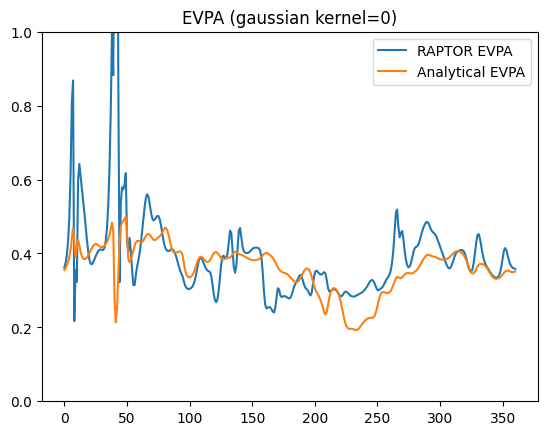

In [22]:
plt.plot(np.linspace(0,360,360),_fit_cos_evpa_A_only(_EVPA_1d1600[0])/np.pi*180,label='RAPTOR EVPA')
plt.plot(np.linspace(0,360,360),_fit_cos_evpa_A_only(analytical_EVPA_after_imageS_1d[0])/np.pi*180,label='Analytical EVPA')
plt.legend()
plt.ylim(0,1)
plt.title("EVPA (gaussian kernel=0)")

analytical的有两种算法：

1.不考虑P的模和辐角

2.考虑P的模和辐角

1.RAPTOR结果将赤道面上j设为一个给定值，EVPA转圈，r方向取~5.5的gaussian，关闭其他地方效应
j的给定值可以如下：

2.赤道面用原有GRMHD的结果，其他地方关闭

3.正常RAPTOR的结果

2x3

400跑一个，100跑alpha=0.3的141个

Text(0.5, 1.0, 'EVPA (whole disk) (gaussian kernel=2.17)')

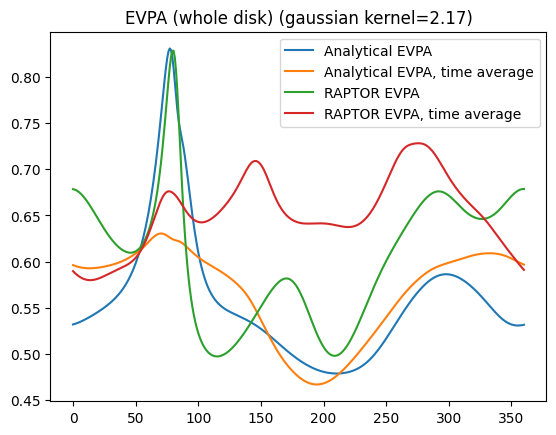

In [37]:
# plt.plot(np.linspace(0,360,360),_analytical_A_no_blur[0:1].mean(axis=0)/np.pi*180,label='Analytical EVPA')
# plt.plot(np.linspace(0,360,360),_analytical_A_no_blur.mean(axis=0)/np.pi*180,label='Analytical EVPA, time average')
plt.plot(np.linspace(0,360,360),_analytical_A[0:1].mean(axis=0)/np.pi*180,label='Analytical EVPA')
plt.plot(np.linspace(0,360,360),_analytical_A.mean(axis=0)/np.pi*180,label='Analytical EVPA, time average')
# plt.plot(np.linspace(0,360,360),_fit_cos_evpa_A_only(_EVPA_1d1600[0])/np.pi*180,label='RAPTOR EVPA')
# plt.plot(np.linspace(0,360,360),_fit_cos_evpa_A_only(analytical_EVPA_after_imageS_1d[0])/np.pi*180,label='Analytical EVPA')
# plt.plot(np.linspace(0,360,360),_tmp[0:1].mean(axis=0)/np.pi*180,label='RAPTOR EVPA')
# plt.plot(np.linspace(0,360,360),_tmp[:].mean(axis=0)/np.pi*180,label='RAPTOR EVPA, time average')
plt.plot(np.linspace(0,360,360),EVPA_fit_result_1d[0:1,:,0].mean(axis=0)/np.pi*180,label='RAPTOR EVPA')
plt.plot(np.linspace(0,360,360),EVPA_fit_result_1d[:,:,0].mean(axis=0)/np.pi*180,label='RAPTOR EVPA, time average')
# plt.plot(np.linspace(0,360,360),_tmp[99:100].mean(axis=0)/np.pi*180)
# plt.ylim(0,1)
plt.legend()
# plt.ylim(0,1)
plt.title("EVPA (whole disk) (gaussian kernel=2.17)")

Text(0.5, 1.0, 'EVPA (gaussian kernel=2.17)')

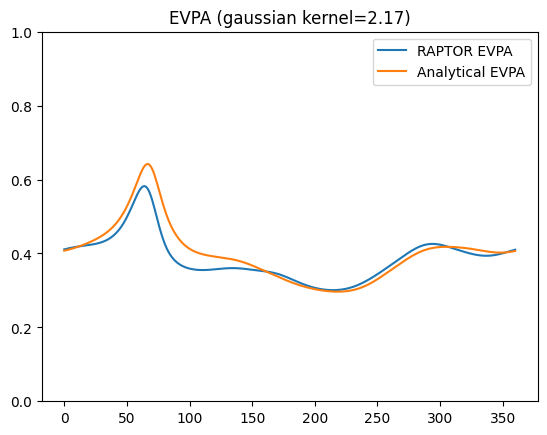

In [25]:
# plt.plot(np.linspace(0,360,360),_analytical_A_no_blur.mean(axis=0)/np.pi*180)
# plt.plot(np.linspace(0,360,360),_analytical_A.mean(axis=0)/np.pi*180)
plt.plot(np.linspace(0,360,360),_fit_cos_evpa_A_only(_EVPA_1d1600[0])/np.pi*180,label='RAPTOR EVPA')
plt.plot(np.linspace(0,360,360),_fit_cos_evpa_A_only(analytical_EVPA_after_imageS_1d[0])/np.pi*180,label='Analytical EVPA')
plt.legend()
plt.ylim(0,1)
plt.title("EVPA (gaussian kernel=2.17)")
# plt.plot(np.linspace(0,360,360),EVPA_fit_result_1d[:,:,0].mean(axis=0)/np.pi*180)
# plt.plot(np.linspace(0,360,360),_tmp[:].mean(axis=0)/np.pi*180)
# plt.plot(np.linspace(0,360,360),EVPA_fit_result_1d[99:100,:,0].mean(axis=0)/np.pi*180)
# plt.plot(np.linspace(0,360,360),_tmp[99:100].mean(axis=0)/np.pi*180)
# plt.ylim(0,1)

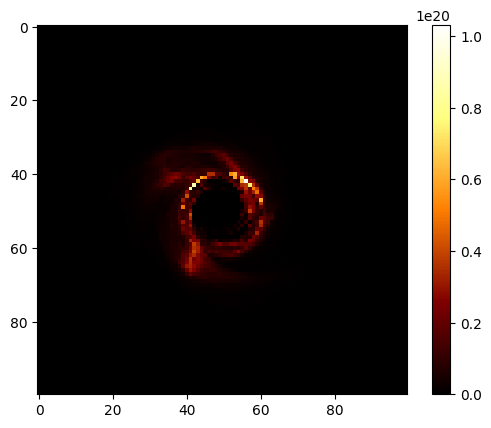

In [101]:
plt.imshow(grmhdDataOrigin[99,0,:,:,0],cmap="afmhot")
plt.colorbar()

In [ ]:
analytical_data=np.zeros((100,100,4))
analytical_data[:,:,0]=grmhdDataOrigin[:,0,:,:,0].mean(axis=0)

x_coords=np.tile(np.linspace(-49.5, 49.5, 100), (100, 1))* 46.2262 / 99
y_coords=np.tile(np.linspace(-49.5, 49.5, 100).reshape(100, 1), (1, 100))* 46.2262 / 99
analytical_data[:,:,1]=np.cos(_phi_trace(x_coords,y_coords))*analytical_data[:,:,0]
analytical_data[:,:,2]=np.sin(_phi_trace(x_coords,y_coords))*analytical_data[:,:,0]
analytical_data[:,:,3]=0


analytical_data_after_imageS,analytical_EVPA_after_imageS,analytical_EVPA_after_imageS_1d=getGRMHDDataAfterImageS(analytical_data[np.newaxis,np.newaxis,...])




0


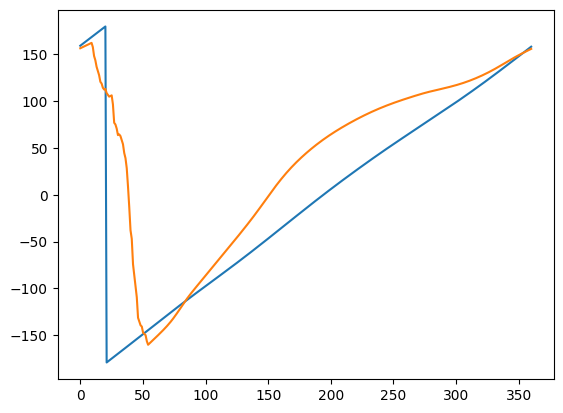

In [59]:
_analytical_phi=(analytical_EVPA_after_imageS_1d[0,0,:]/np.pi*180+0.4*180)*2
_analytical_phi[_analytical_phi>180]-=360
plt.plot(np.linspace(0,360,360),_analytical_phi)
plt.plot(np.linspace(0,360,360),EVPA_fit_result_1d[:,:,1].mean(axis=0)/np.pi*180)

In [ ]:
grmhdDataOrigin=np.load("data/grmhdDataOrigin.npy",allow_pickle=True)

_tmp=np.zeros((141,100,100))
for i in range(141):
    _tmp[i,:,:]=_fit_cos_evpa_A_only(0.5*np.arctan2(grmhdDataOrigin[i,:,:,:,2],grmhdDataOrigin[i,:,:,:,1]))

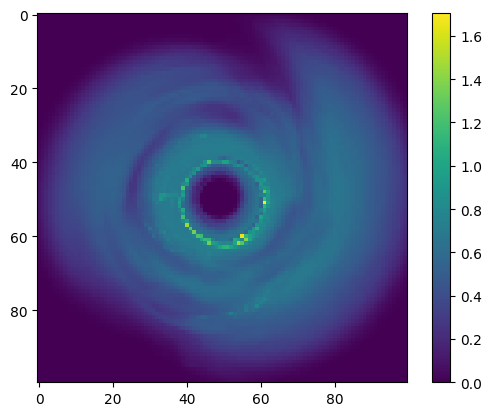

In [68]:
plt.imshow(_tmp[:,:,:].mean(axis=0)/np.pi*180)
plt.colorbar()
# plt.clim(0,0.1/2/np.pi/np.pi*180)

0


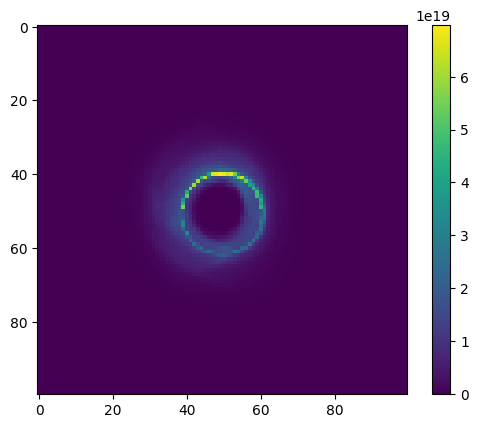

In [39]:
plt.imshow(grmhdDataOrigin[:,0,:,:,0].mean(axis=0))
plt.colorbar()

In [51]:
_EVPA_1d1600.shape

(1, 17, 360)